# Water Rights Restored to the Gila River

The impacts of irrigation on vegetation health in the Gila River Valley


## Set up

To get started on this notebook, you’ll need to restore any variables from previous notebooks to your workspace. To save time and memory, make sure to specify which variables you want to load.

In [1]:
%store -r 

ndvi_diff = ndvi_post - ndvi_pre

Unable to restore variable 'ndvi_diff', ignoring (use %store -d to forget!)
The error was: <class 'KeyError'>


You will also need to import any libraries you are using in this
notebook, since they won’t carry over from the previous notebook:

In [21]:
### import libraries
### working with dataframes
import pandas as pd


### working with geodataframes
import geopandas as gpd

### making interactive plots of tabular and vector data
import hvplot.pandas

### work with json data
import json

### work with pattern matching rules for pathnames 
from glob import glob

### access the data we'll use for the assignment
import earthpy

### interactive plots with rasters 
import hvplot.xarray

### handle geospatial rasters
import rioxarray as rxr

### work with arrays
import xarray as xr

### work with maps
import cartopy.crs as ccrs


## Step 5: Is the mean annual July NDVI different within the Gila River Indian Community after the change in water rights?

You will compute the mean NDVI inside and outside the Reservation boundary. 

### Step 5A: Get the NDVI inside and outside the Gila River Indian Community

First, use the code below to get a `GeoDataFrame` of the area outside the Reservation.

- Check the variable names. Make sure that the code uses your boundary `GeoDataFrame`  
- How could you test if the geometry was modified correctly? Add some code to take a look at the results

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

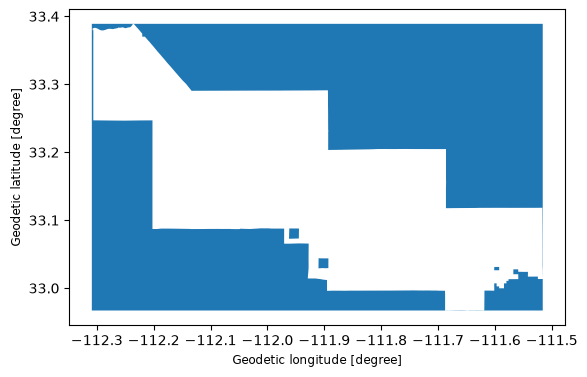

In [3]:
### compute the area outside the reservation boundary
out_gdf = (
    gpd.GeoDataFrame(geometry = boundary_gdf.envelope)
    .overlay(boundary_gdf, how = 'difference'))

### check that the area outside the reservation boundary was calculated correctly
out_gdf.plot()

Next, clip your DataArray to the boundaries for both inside and outside
the reservation. You will need to replace the `GeoDataFrame` name with
your own. Check out the [lesson on clipping data with the `rioxarray`
library on EarthDataScience.org](https://www.earthdatascience.org/courses/use-data-open-source-python/intro-raster-data-python/raster-data-processing/crop-raster-data-with-shapefile-in-python/).

**Note**: It’s important to use `from_disk = True` when clipping large arrays like this. It allows the computer to use less valuable memory resources when clipping. Otherwise, you will probably find that the cell below crashes your kernel.

In [4]:
### clip data to inside the reservation's boundaries
ndvi_in_da = ndvi_da.rio.clip(boundary_gdf.geometry, from_disk = True)

### clip data to outside the reservation's boundaries 
ndvi_out_da = ndvi_da.rio.clip(out_gdf.geometry, from_disk = True)


### Step 5B: Assess the change in NDVI before and after the change in water rights, inside and outside the boundaries of the Gila River Indian Community

For **both inside and outside** the Gila River Indian Community boundary, calculate the mean annual July NDVI:  

- Group the data by year  
- Take the mean. You always need to tell reducing methods in `xarray` what dimensions you want to reduce. When you want to summarize data across **all** dimensions, you can use the `...` syntax, e.g. `.mean(...)` as a shorthand  
- Select the NDVI variable  
- Convert to a DataFrame using the `to_dataframe()` method  
- Join the two DataFrames for plotting using the `.join()` method. You will need to rename the columns using the `lsuffix =` and `rsuffix =` parameters
- Finally, plot annual July means for both inside and outside the Reservation on the same plot.

**Note**: The DateIndex in pandas is a little different from the Datetime Dimension in xarray. You will need to use the `.dt.year` syntax to access information about the year, not just `.year`.

In [ ]:
### calculate mean annual July NDVI inside
july_ndvi_in_df = (
    ndvi_in_da 
    
    ### group by year
    .groupby(ndvi_in_da.date.dt.year)

    ### calculate the mean for each year, 
    # averaging values across all dates and all pixels in that year
    .mean(...)

    ### convert to a dataframe
    .NDVI.to_dataframe()
)
july_ndvi_in_df
### calculate mean annual July NDVI outside
july_ndvi_out_df = (
    ndvi_out_da
    
    ### group by year
    .groupby(ndvi_out_da.date.dt.year)

    ### calculate the mean for each year
    .mean(...)

    ### convert to a dataframe
    .NDVI.to_dataframe()
)
july_ndvi_out_df

### plot inside and outside the reservation on a single plot
### join inside and outside data
july_ndvi_df = (

    ### get NDVI from inside
    july_ndvi_in_df[['NDVI']]

    ### join to NDVI from outside
    .join(

        ### get NDVI from outside
        july_ndvi_out_df[['NDVI']],

        ### make columne names for NDVI distinct between inside and outside GRIC
        lsuffix = ' inside GRIC', rsuffix = ' outside GRIC'
    )
)

C:\Users\greta\AppData\Local\Temp\ipykernel_15288\1912152863.py:37: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  .join(


Now, take the difference between outside and inside the site boundary and plot that


In [6]:
### calculate difference in mean July NDVI by subtracting outside mean from inside mean
july_ndvi_df['difference'] = (
    july_ndvi_df['NDVI inside GRIC']
    -july_ndvi_df['NDVI outside GRIC']
)

### plot difference inside and outside the boundary
july_ndvi_df.difference.hvplot(
    title = 'Difference between NDVI inside and outside of the Gila River Indian Community over time'
)

:Curve   [year]   (difference)

In [ ]:
### plot inside and outside next to eachother
july_ndvi_df.hvplot(
    title = 'changes in NDVI inside and outside of the Gila River Indian Community over time',
    y=["NDVI inside GRIC", "NDVI outside GRIC"],
)

### save plot


:NdOverlay   [Variable]
   :Curve   [year]   (value)

### Reflect and Respond #6:
What do you observe? Don’t forget to write a headline and description of your plot!

## NDVI Values Increase for the Gila River Indian Community after the Arizona Water Settlements Act of 2004

The Gila River Indian Community (GRIC) is located right outside of Phoenix, AZ. An area well-known in the west for it's ever increasing use of water for lawns, golf courses, swimming pools, and more recently data centers. When you fly into Phoenix there is an obvious shift in the landscape from the oranges, reds, and browns of the desert to the vibrant green of downtown Phoenix. Where is all of this water coming from and how does that impact the Indigenous Communities that surround the city. 

The Gila River flows west out of New Mexico and into Arizona. Indigenous People have utilized this area for agriculture for thousands of years. In the 1870s and 80s as white settlers moved West, dams were created which cut off the GRICs access to water from the Gila. This had a large impact on agriculture and overall health and well-being of the tribe. In 2004, the GRIC settled over water disputes with the state of Arizona and was awarded an annual CAP of over 300,000 acre feet of water. For context, the average household uses less than 3 acre feet of water per year and the GRIC were initally using only about 50,000 acre-feet in a year. However, since 2010 the GRIC have developed new ways to better utilize their water resources. INSERT THOSE WAYS HERE. 

We chose to ways to look at the change in NDVI values over time. The first was to compare NDVI values from 2001-2007, to values from 2013 to 2022 in a vegetaion plot. The second was to graph the difference in NDVI change over time inside and outside of the GRIC boundary. The Vegetation Plot shows an increase in agricultural production inside GRIC since 2007 when the water rights case went into effect. The darker green areas show the greatest increase in NDVI values whereas the pink areas show the greatest decrease in NDVI vales. Many of the pinkest areas are outside of the GRIC boundary and seem to line up with Phoenix public parks. The graph shows that overtime the difference between NDVI outside of the GRIC and inside of the GRIC is decreasing. Initially, the NDVI outside of the GRIC was almost .5 higher than inside, in recent years that numbers has decreased to approximately .1. 

It is great to see an increase in vegetaion in the GRIC and to read about the practices and techniques being utilized by the GRIC to be strong stewards to the river and the land. 

## Wrap up

Don’t forget to store your variables so you can use them in other notebooks! Replace `var1` and `var2` with the variable you want to save, separated by spaces.

In [7]:
%store july_ndvi_df out_gdf

Stored 'july_ndvi_df' (DataFrame)
Stored 'out_gdf' (GeoDataFrame)


Finally, be sure to `Restart` and `Run all` to make sure your notebook
works all the way through!